In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

In [112]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise= 20, random_state=2)

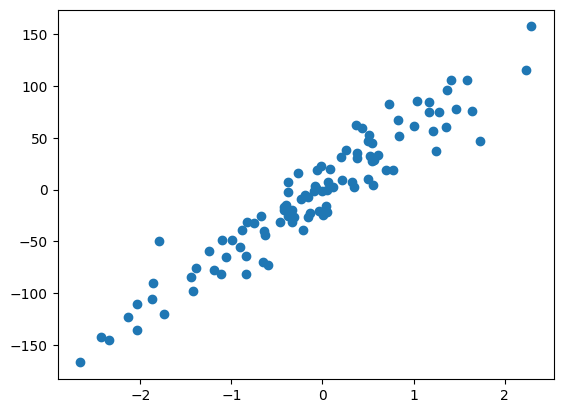

In [113]:
plt.scatter(X,y)

In [114]:
from sklearn.model_selection import train_test_split
X_train, x_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [115]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train,y_train)
lr.coef_

array([57.25933739])

In [116]:
lr.intercept_

np.float64(-0.20094647599604976)

In [117]:
y_pred = lr.predict(x_test)

In [118]:
from sklearn.metrics import r2_score

r2_score(y_test, y_pred)

0.9095184055289018

In [119]:
class GDRegressor:

    def __init__(self,learning_rate=0.01, epochs=100,slope=1,intercept=1):
        self.alfa = learning_rate
        self.epochs = epochs
        self.m = slope
        self.b = intercept

    def fit(self,X_train, y_train):
        X_train = X_train.ravel()
        y_train = y_train.ravel()
        n = len(X_train)
        for i in range(self.epochs):
            db = -2 * np.sum(y_train - self.m*X_train - self.b)/n
            dm = -2 * np.sum((y_train - self.m*X_train - self.b)*X_train)/n
            self.b = self.b - self.alfa*db
            self.m = self.m - self.alfa*dm

    def predict(self,X_test):
        X_test = X_test.ravel()
        return self.m * X_test + self.b



In [120]:
lr = GDRegressor(learning_rate=0.01,epochs=1000,slope=1,intercept=4)

lr.fit(X_train,y_train)

In [121]:
print(lr.m)
print(lr.b)

57.25933729014596
-0.20094666183367468


In [122]:
y_pred = lr.predict(x_test)

In [123]:
r2_score(y_test,y_pred)

0.9095184048225411